# Streamflow seasonality and trend: Mississippi River at St. Paul, MN

**Question:** What is the seasonal flow pattern of the Mississippi River at St. Paul, and has annual mean flow or annual flood size changed over water years 1991 to 2025?

**Data:** USGS station 05331000, daily mean discharge, downloaded with the `dataretrieval` Python package (USGS Water Data API).

**Methods:** pandas for cleaning and grouping, Mann-Kendall trend test and Sen's slope (`pymannkendall`), figures with Matplotlib.

**Author:** Imranur Rahman. Built using library documentation and AI-assisted coding. I have gone through and understood every line.

## 1. Setup and data download

In [1]:
!pip install dataretrieval pymannkendall --quiet   # "!" runs a system command; pip installs the USGS download library and the Mann-Kendall library; --quiet hides the long install messages

In [2]:
import pandas as pd                    # pandas works with tables of data, like Excel inside Python; "pd" is a short nickname
import numpy as np                     # NumPy does fast maths on lists of numbers; "np" is its nickname
import matplotlib.pyplot as plt        # Matplotlib draws graphs; "plt" is the nickname everyone uses
from dataretrieval import waterdata    # from the USGS library, load only the "waterdata" part (the new data service)

In [3]:
site_id = "USGS-05331000"              # station ID: Mississippi River at St. Paul, MN (new service needs "USGS-" in front)
param_code = "00060"                   # USGS code for discharge (streamflow), measured in cubic feet per second (cfs)
stat_code = "00003"                    # USGS code for "daily mean", so we get one average value per day
date_range = "1990-10-01/2025-09-30"   # start date / end date: 35 full water years

raw_df, metadata = waterdata.get_daily(  # ask USGS for daily data; it returns two things: the data table and some info about the request
    monitoring_location_id=site_id,      # which station
    parameter_code=param_code,           # which variable
    statistic_id=stat_code,              # which daily statistic
    time=date_range,                     # which period
)

In [4]:
print(type(raw_df))              # what kind of object we got back (should be a table / DataFrame)
print(raw_df.shape)              # (number of rows, number of columns); 35 years should give about 12,780 rows
print(raw_df.columns.tolist())   # list of all column names, so we know what USGS sent
raw_df.head()                    # show the first 5 rows (no print needed when it is the last line of a cell)

<class 'geopandas.geodataframe.GeoDataFrame'>
(12784, 12)
['geometry', 'time_series_id', 'monitoring_location_id', 'parameter_code', 'statistic_id', 'time', 'value', 'unit_of_measure', 'approval_status', 'qualifier', 'last_modified', 'daily_id']


,geometry,time_series_id,monitoring_location_id,parameter_code,statistic_id,time,value,unit_of_measure,approval_status,qualifier,last_modified,daily_id
0,POINT (-93.08811 44.94444),db30e0869a2a413e995cdc4a10d0fc5b,USGS-05331000,00060,00003,1990-10-01,4170.0,ft^3/s,Approved,None,2025-03-11 07:56:58.928100+00:00,02aa8b3f-24a9-4a4c-a0db-4f1a7a16656e
1,POINT (-93.08811 44.94444),db30e0869a2a413e995cdc4a10d0fc5b,USGS-05331000,00060,00003,1990-10-02,3600.0,ft^3/s,Approved,None,2025-03-11 07:56:58.928100+00:00,7ae5383e-9d1e-4f99-9f22-0e509d8ea30e
2,POINT (-93.08811 44.94444),db30e0869a2a413e995cdc4a10d0fc5b,USGS-05331000,00060,00003,1990-10-03,3500.0,ft^3/s,Approved,None,2025-03-11 07:56:58.928100+00:00,41d65cc8-ddbb-477f-bbad-d31f453a8aca
3,POINT (-93.08811 44.94444),db30e0869a2a413e995cdc4a10d0fc5b,USGS-05331000,00060,00003,1990-10-04,3960.0,ft^3/s,Approved,None,2025-03-11 07:56:58.928100+00:00,335a7c8d-c89d-4bbc-8c42-b668251c20b9
4,POINT (-93.08811 44.94444),db30e0869a2a413e995cdc4a10d0fc5b,USGS-05331000,00060,00003,1990-10-05,4850.0,ft^3/s,Approved,None,2025-03-11 07:56:58.928100+00:00,e79c34cb-eefd-47a5-8165-16bbe7dea8d1


## 2. Cleaning and quality check
The record is complete: 12,784 days, no missing dates, no empty values. All data is USGS "Approved". About 23% of days are flagged "estimated", mostly in December to February, when river ice affects the gauge. None of the 35 annual peak flows fall on estimated days.

In [5]:
df = pd.DataFrame(raw_df[["time", "value", "approval_status", "qualifier"]])  # keep only 4 useful columns; pd.DataFrame() turns it into a plain pandas table (drops the map part)
df["time"] = pd.to_datetime(df["time"])       # turn the date text into real dates, so Python knows 1990-10-01 is a day, not just text
df = df.set_index("time").sort_index()        # make the date the row label (the "index") and put rows in date order
df = df.rename(columns={"value": "Q_cfs"})    # rename "value" to "Q_cfs"; Q is the standard hydrology symbol for discharge
df["Q_cms"] = df["Q_cfs"] * 0.0283168         # new column in cubic metres per second (m³/s), since 1 ft³/s = 0.0283168 m³/s
df.head()                                     # show the first 5 rows to check

,Q_cfs,approval_status,qualifier,Q_cms
time,,,,
1990-10-01,4170.0,Approved,None,118.081056
1990-10-02,3600.0,Approved,None,101.940480
1990-10-03,3500.0,Approved,None,99.108800
1990-10-04,3960.0,Approved,None,112.134528
1990-10-05,4850.0,Approved,None,137.336480


In [6]:
print("First date:", df.index.min())                     # earliest date in the data
print("Last date:", df.index.max())                      # latest date in the data
all_days = pd.date_range(df.index.min(), df.index.max(), freq="D")  # make a list of every calendar day between those two dates
print("Days expected:", len(all_days))                   # how many days there should be
print("Days we have:", len(df))                          # how many rows we actually have
print("Missing days:", len(all_days.difference(df.index)))  # days on the calendar that are not in our data
print("Empty values (NaN):", df["Q_cfs"].isna().sum())   # rows that exist but have no discharge number (NaN = "not a number")
print("Duplicate dates:", df.index.duplicated().sum())   # same date appearing twice (should be 0)
print()                                                  # print an empty line, just for spacing
print(df["approval_status"].value_counts())              # count of Approved vs Provisional rows
print()                                                  # empty line again
print(df["qualifier"].astype(str).value_counts())        # count of each special flag; astype(str) turns flags into text so they can be counted

First date: 1990-10-01 00:00:00
Last date: 2025-09-30 00:00:00
Days expected: 12784
Days we have: 12784
Missing days: 0
Empty values (NaN): 0
Duplicate dates: 0

approval_status
Approved    12784
Name: count, dtype: int64

qualifier
None                                   9840
['ESTIMATED']                          2929
['FORCEINTERPOLATION']                   13
['ESTIMATED', 'FORCEINTERPOLATION']       2
Name: count, dtype: int64


In [7]:
df["Q_cms"].describe()     # count, mean, standard deviation, min, 25%, 50% (median), 75%, max of discharge in m³/s

,Q_cms
count,12784.000000
mean,529.324631
std,497.923035
min,57.766272
25%,192.554240
50%,353.960000
75%,702.256640
max,4020.985600


## 3. Monthly, seasonal and annual flow
A water year runs from 1 October to 30 September, so each winter's snow and the spring melt it produces fall in the same year.

In [8]:
df["month"] = df.index.month                                 # take the month number (1 to 12) from each date
df["water_year"] = df.index.year + (df.index.month >= 10)    # Oct, Nov, Dec count in the NEXT water year; (month >= 10) is True=1 or False=0, so it adds 1 or 0
season_map = {12: "Winter", 1: "Winter", 2: "Winter",        # a lookup table: month number -> season name (Dec, Jan, Feb = Winter)
              3: "Spring", 4: "Spring", 5: "Spring",         # Mar, Apr, May = Spring
              6: "Summer", 7: "Summer", 8: "Summer",         # Jun, Jul, Aug = Summer
              9: "Autumn", 10: "Autumn", 11: "Autumn"}       # Sep, Oct, Nov = Autumn
df["season"] = df["month"].map(season_map)                   # for each row, look up its month in the table and write the season
df.head()                                                    # check: 1 Oct 1990 should show water_year 1991 and season Autumn

,Q_cfs,approval_status,qualifier,Q_cms,month,water_year,season
time,,,,,,,
1990-10-01,4170.0,Approved,None,118.081056,10,1991,Autumn
1990-10-02,3600.0,Approved,None,101.940480,10,1991,Autumn
1990-10-03,3500.0,Approved,None,99.108800,10,1991,Autumn
1990-10-04,3960.0,Approved,None,112.134528,10,1991,Autumn
1990-10-05,4850.0,Approved,None,137.336480,10,1991,Autumn


In [9]:
monthly_mean = df.groupby("month")["Q_cms"].mean()   # pivot table: rows = month, value = average discharge
print(monthly_mean.round(1))                          # show the result rounded to 1 decimal place

month
1      222.0
2      208.0
3      490.0
4     1067.7
5      988.8
6      877.8
7      713.3
8      389.8
9      329.9
10     413.9
11     365.7
12     273.6
Name: Q_cms, dtype: float64


In [10]:
seasonal_mean = df.groupby("season")["Q_cms"].mean()                         # pivot table: rows = season, value = average discharge
seasonal_mean = seasonal_mean.reindex(["Winter", "Spring", "Summer", "Autumn"])  # put seasons in calendar order (by default pandas sorts alphabetically)
print(seasonal_mean.round(1))                                                  # show rounded result

season
Winter    235.3
Spring    846.4
Summer    657.9
Autumn    370.3
Name: Q_cms, dtype: float64


In [11]:
annual = pd.DataFrame({                                                  # build a new table with one row per water year
    "mean_Q_cms": df.groupby("water_year")["Q_cms"].mean(),              # average flow in that water year
    "peak_Q_cms": df.groupby("water_year")["Q_cms"].max(),               # highest daily flow in that water year (the annual flood)
    "peak_date": df.groupby("water_year")["Q_cms"].idxmax(),             # the date on which that highest flow happened (idxmax = "where is the max")
})
print(annual.round(1))                                                   # show all 35 rows
print("Number of water years:", len(annual))                            # should be 35

            mean_Q_cms  peak_Q_cms  peak_date
water_year                                   
1991             450.0      1472.5 1991-05-13
1992             454.2      1373.4 1992-03-14
1993             817.5      2944.9 1993-06-26
1994             569.7      1667.9 1994-05-05
1995             579.7      1520.6 1995-04-28
1996             556.3      1430.0 1996-04-23
1997             657.2      3766.1 1997-04-12
1998             422.7      1526.3 1998-04-09
1999             523.8      1744.3 1999-05-21
2000             273.0       696.6 2000-07-17
2001             676.7      4021.0 2001-04-18
2002             401.2      1217.6 2002-06-30
2003             356.9      1070.4 2003-07-01
2004             282.9      1328.1 2004-06-16
2005             460.8      1336.6 2005-06-17
2006             497.4      1718.8 2006-04-13
2007             301.5      1379.0 2007-04-05
2008             409.7      1342.2 2008-05-11
2009             327.7      1752.8 2009-03-31
2010             579.2      2775.0

## 4. Trend test: Mann-Kendall and Sen's slope
Mann-Kendall compares every year with every later year and checks whether later years are more often higher or lower. It does not assume normally distributed data, which suits skewed river flows. Sen's slope is the median of the slopes between all pairs of years, so single extreme floods do not distort it much. Lag-1 autocorrelation was checked first (0.18 for annual mean, -0.11 for annual peak), so the standard test is valid.

In [12]:
est = df["qualifier"].astype(str).str.contains("ESTIMATED")   # True for each day whose flag includes "ESTIMATED", False otherwise
print(est.groupby(df["month"]).sum())                         # pivot: rows = month, value = number of estimated days (True counts as 1)

month
1     779
2     654
3     349
4      32
5      58
6      18
7      45
8      52
9      66
10    108
11    161
12    609
Name: qualifier, dtype: int64


In [13]:
annual["peak_month"] = annual["peak_date"].dt.month             # take the month number out of each peak date
print(annual["peak_month"].value_counts().sort_index())          # count how many annual floods happened in each month, in month order

peak_month
3     5
4    10
5     8
6     7
7     4
9     1
Name: count, dtype: int64


In [14]:
for col in ["mean_Q_cms", "peak_Q_cms"]:                  # repeat the steps below for each of these two columns
    r1 = annual[col].autocorr(lag=1)                      # correlation between each year's value and the previous year's value
    print(col, "lag-1 autocorrelation:", round(r1, 2))    # show it rounded to 2 decimals

mean_Q_cms lag-1 autocorrelation: 0.18
peak_Q_cms lag-1 autocorrelation: -0.11


In [15]:
import pymannkendall as mk                                    # load the Mann-Kendall library installed in Cell 1

for col in ["mean_Q_cms", "peak_Q_cms"]:                      # test both yearly mean flow and yearly peak flow
    result = mk.original_test(annual[col])                    # run the Mann-Kendall test on the 35 yearly values
    print("Series:", col)                                     # which series this result is for
    print("  Trend:", result.trend)                           # 'increasing', 'decreasing' or 'no trend'
    print("  p-value:", round(result.p, 4))                   # below 0.05 = significant trend
    print("  Kendall's tau:", round(result.Tau, 3))           # strength and direction, -1 to +1
    print("  Sen's slope (m3/s per year):", round(result.slope, 2))  # change per year, robust to extreme years
    print()                                                   # blank line between the two results

Series: mean_Q_cms
  Trend: no trend
  p-value: 0.57
  Kendall's tau: 0.069
  Sen's slope (m3/s per year): 1.49

Series: peak_Q_cms
  Trend: no trend
  p-value: 0.2441
  Kendall's tau: 0.139
  Sen's slope (m3/s per year): 15.07



In [16]:
annual["peak_estimated"] = est.loc[annual["peak_date"]].values           # for each year's peak date, look up whether that day was ESTIMATED (True/False)
print("Peaks on estimated days:", annual["peak_estimated"].sum(), "of", len(annual))  # how many of the 35 floods fall on estimated days
print(annual.loc[annual["peak_estimated"], ["peak_Q_cms", "peak_date"]])  # list those years, if any

Peaks on estimated days: 0 of 35
Empty DataFrame
Columns: [peak_Q_cms, peak_date]
Index: []


## 5. Figures

In [17]:
plt.rcParams["axes.spines.top"] = False      # remove the top border line around each plot (cleaner look)
plt.rcParams["axes.spines.right"] = False    # remove the right border line too
plt.rcParams["axes.grid"] = True             # turn on background grid lines
plt.rcParams["grid.alpha"] = 0.3             # make grid lines faint (0 = invisible, 1 = solid)
blue = "#2a6f97"                             # main colour for data, written as a hex colour code
orange = "#d9822b"                           # second colour, used only for the trend line

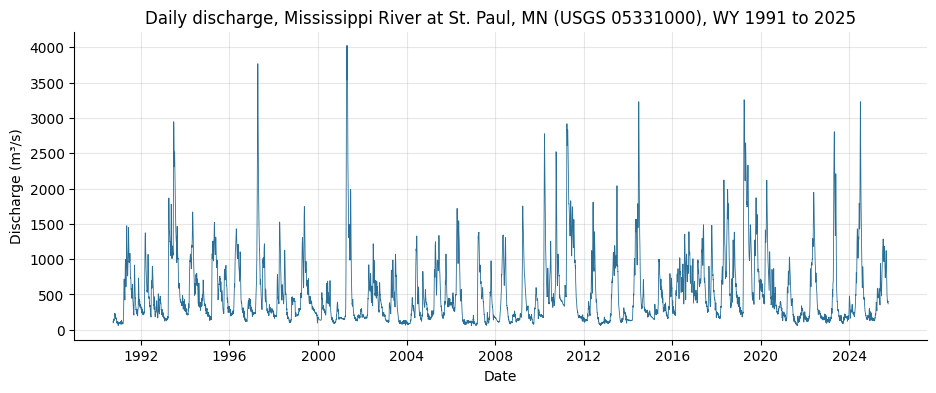

In [18]:
fig, ax = plt.subplots(figsize=(11, 4))                          # create a blank figure (fig) with one plot area (ax), 11 x 4 inches
ax.plot(df.index, df["Q_cms"], color=blue, linewidth=0.6)        # draw daily discharge against date as a thin line
ax.set_xlabel("Date")                                            # x-axis label
ax.set_ylabel("Discharge (m³/s)")                                # y-axis label
ax.set_title("Daily discharge, Mississippi River at St. Paul, MN (USGS 05331000), WY 1991 to 2025")  # title
fig.savefig("fig1_hydrograph.png", dpi=200, bbox_inches="tight") # save as an image file; dpi=200 = sharp; "tight" trims extra white space
plt.show()                                                       # display the figure below the cell

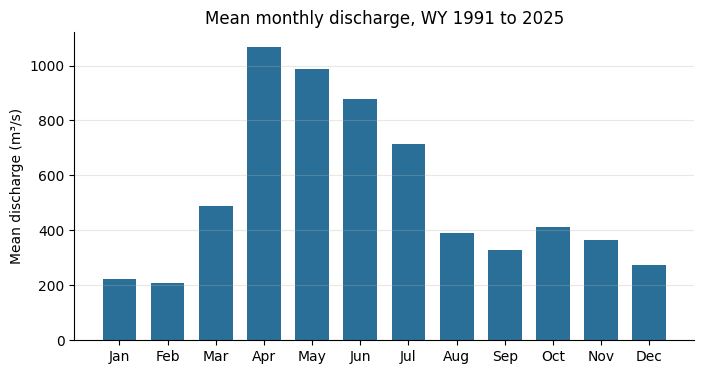

In [19]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]        # labels for the 12 bars
fig, ax = plt.subplots(figsize=(8, 4))                          # blank figure, 8 x 4 inches
ax.bar(month_names, monthly_mean.values, color=blue, width=0.7) # one bar per month; height = average flow from Cell 9
ax.grid(axis="x", visible=False)                                # hide vertical grid lines (only horizontal ones help read bar heights)
ax.set_ylabel("Mean discharge (m³/s)")                          # y-axis label
ax.set_title("Mean monthly discharge, WY 1991 to 2025")         # title
fig.savefig("fig2_monthly_means.png", dpi=200, bbox_inches="tight")  # save
plt.show()                                                      # display

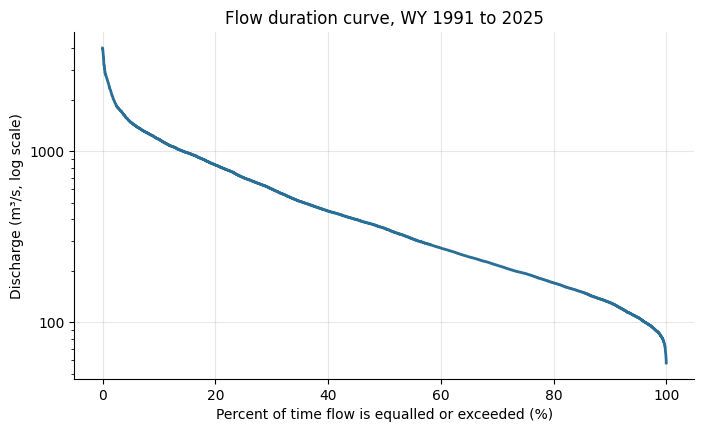

Q10 (high flow, exceeded 10% of time): 1175.1
Q50 (median flow): 354.0
Q90 (low flow, exceeded 90% of time): 130.3


In [20]:
from matplotlib.ticker import ScalarFormatter          # a tool that writes axis numbers as normal numbers

q_sorted = np.sort(df["Q_cms"].values)[::-1]           # all 12,784 daily flows sorted from largest to smallest ([::-1] flips the order)
n = len(q_sorted)                                       # number of days
rank = np.arange(1, n + 1)                              # ranks 1, 2, 3 ... n (rank 1 = biggest flow)
exceed = rank / (n + 1) * 100                           # Weibull formula: % of time each flow is equalled or exceeded

fig, ax = plt.subplots(figsize=(8, 4.5))                # blank figure
ax.plot(exceed, q_sorted, color=blue, linewidth=2)      # draw the curve
ax.set_yscale("log")                                    # log scale on y, so low flows and high flows are both visible
ax.yaxis.set_major_formatter(ScalarFormatter())         # show 100 and 1000 instead of 10² and 10³
ax.set_xlabel("Percent of time flow is equalled or exceeded (%)")  # x-axis label
ax.set_ylabel("Discharge (m³/s, log scale)")            # y-axis label
ax.set_title("Flow duration curve, WY 1991 to 2025")    # title
fig.savefig("fig3_flow_duration_curve.png", dpi=200, bbox_inches="tight")  # save (replaces the old file)
plt.show()                                              # display

print("Q10 (high flow, exceeded 10% of time):", round(np.percentile(df["Q_cms"], 90), 1))  # flow beaten only 10% of days
print("Q50 (median flow):", round(np.percentile(df["Q_cms"], 50), 1))                     # flow beaten half the days
print("Q90 (low flow, exceeded 90% of time):", round(np.percentile(df["Q_cms"], 10), 1))  # flow beaten 90% of days

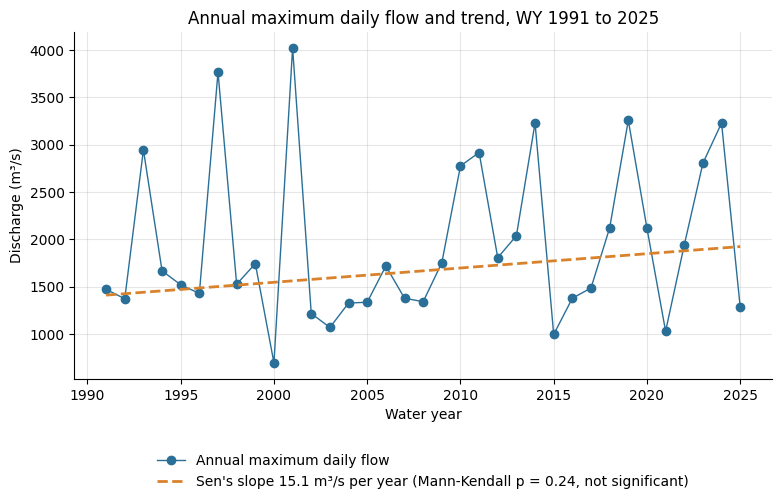

In [21]:
peak_result = mk.original_test(annual["peak_Q_cms"])         # run Mann-Kendall again on peaks and keep the result
years = annual.index.values                                  # the water years, 1991 to 2025
sen_line = peak_result.intercept + peak_result.slope * (years - years[0])  # straight trend line; the library counts time from 0 at the first year
sig_text = "significant" if peak_result.p < 0.05 else "not significant"   # pick the right word based on the p-value

fig, ax = plt.subplots(figsize=(9, 4.5))                     # blank figure
ax.plot(years, annual["peak_Q_cms"], color=blue, linewidth=1,
        marker="o", markersize=6, label="Annual maximum daily flow")       # dots joined by a thin line, one per year
ax.plot(years, sen_line, color=orange, linewidth=2, linestyle="--",
        label=f"Sen's slope {peak_result.slope:.1f} m³/s per year "
              f"(Mann-Kendall p = {peak_result.p:.2f}, {sig_text})")       # dashed trend line; label filled in with real numbers
ax.set_xlabel("Water year")                                  # x-axis label
ax.set_ylabel("Discharge (m³/s)")                            # y-axis label
ax.set_title("Annual maximum daily flow and trend, WY 1991 to 2025")       # title
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18))  # put the legend below the plot so it doesn't hide any data points
fig.savefig("fig4_annual_peak_trend.png", dpi=200, bbox_inches="tight")    # save
plt.show()                                                   # display

In [22]:
annual.to_csv("annual_summary.csv")                 # save the yearly table (mean flow, peak, peak date, peak month, estimated flag) as a CSV file
monthly_mean.round(2).to_csv("monthly_means.csv")   # save the 12 monthly averages, rounded to 2 decimals

## Summary of findings
- **Snowmelt-driven regime.** Mean flow is highest in April (1,068 m³/s) and lowest in February (208 m³/s). Spring flow is about 3.6 times winter flow.
- **Two flood types.** 23 of 35 annual peaks occurred in March to May (snowmelt), and 12 in June to September (likely rainfall).
- **No significant trend.** Annual mean flow: Sen's slope +1.5 m³/s per year, p = 0.57. Annual peak flow: Sen's slope +15.1 m³/s per year, p = 0.24. Both slopes are positive but cannot be separated from year-to-year variability.
- **Possible shift, not tested.** Peaks look lower in 2002 to 2009 and higher from 2010 onwards. Mann-Kendall tests for a steady monotonic trend, not a sudden shift. A change-point test (for example Pettitt) is a possible next step.

**Limitations:** 35 years only (the station record is much longer); annual peaks are daily means, not instantaneous peaks; winter values are largely estimated because of ice.